# Take the first results with ray.wait

Three tasks with different run times feed a Wait node. ray.wait returns as soon as two are done, leaving the slow one running.

**When to use it.** Racing replicas, processing results as they complete, or enforcing a deadline on a batch of tasks.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it, edited by hand so that each function is wrapped with `ray.remote` once (the cell's first line says so). The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

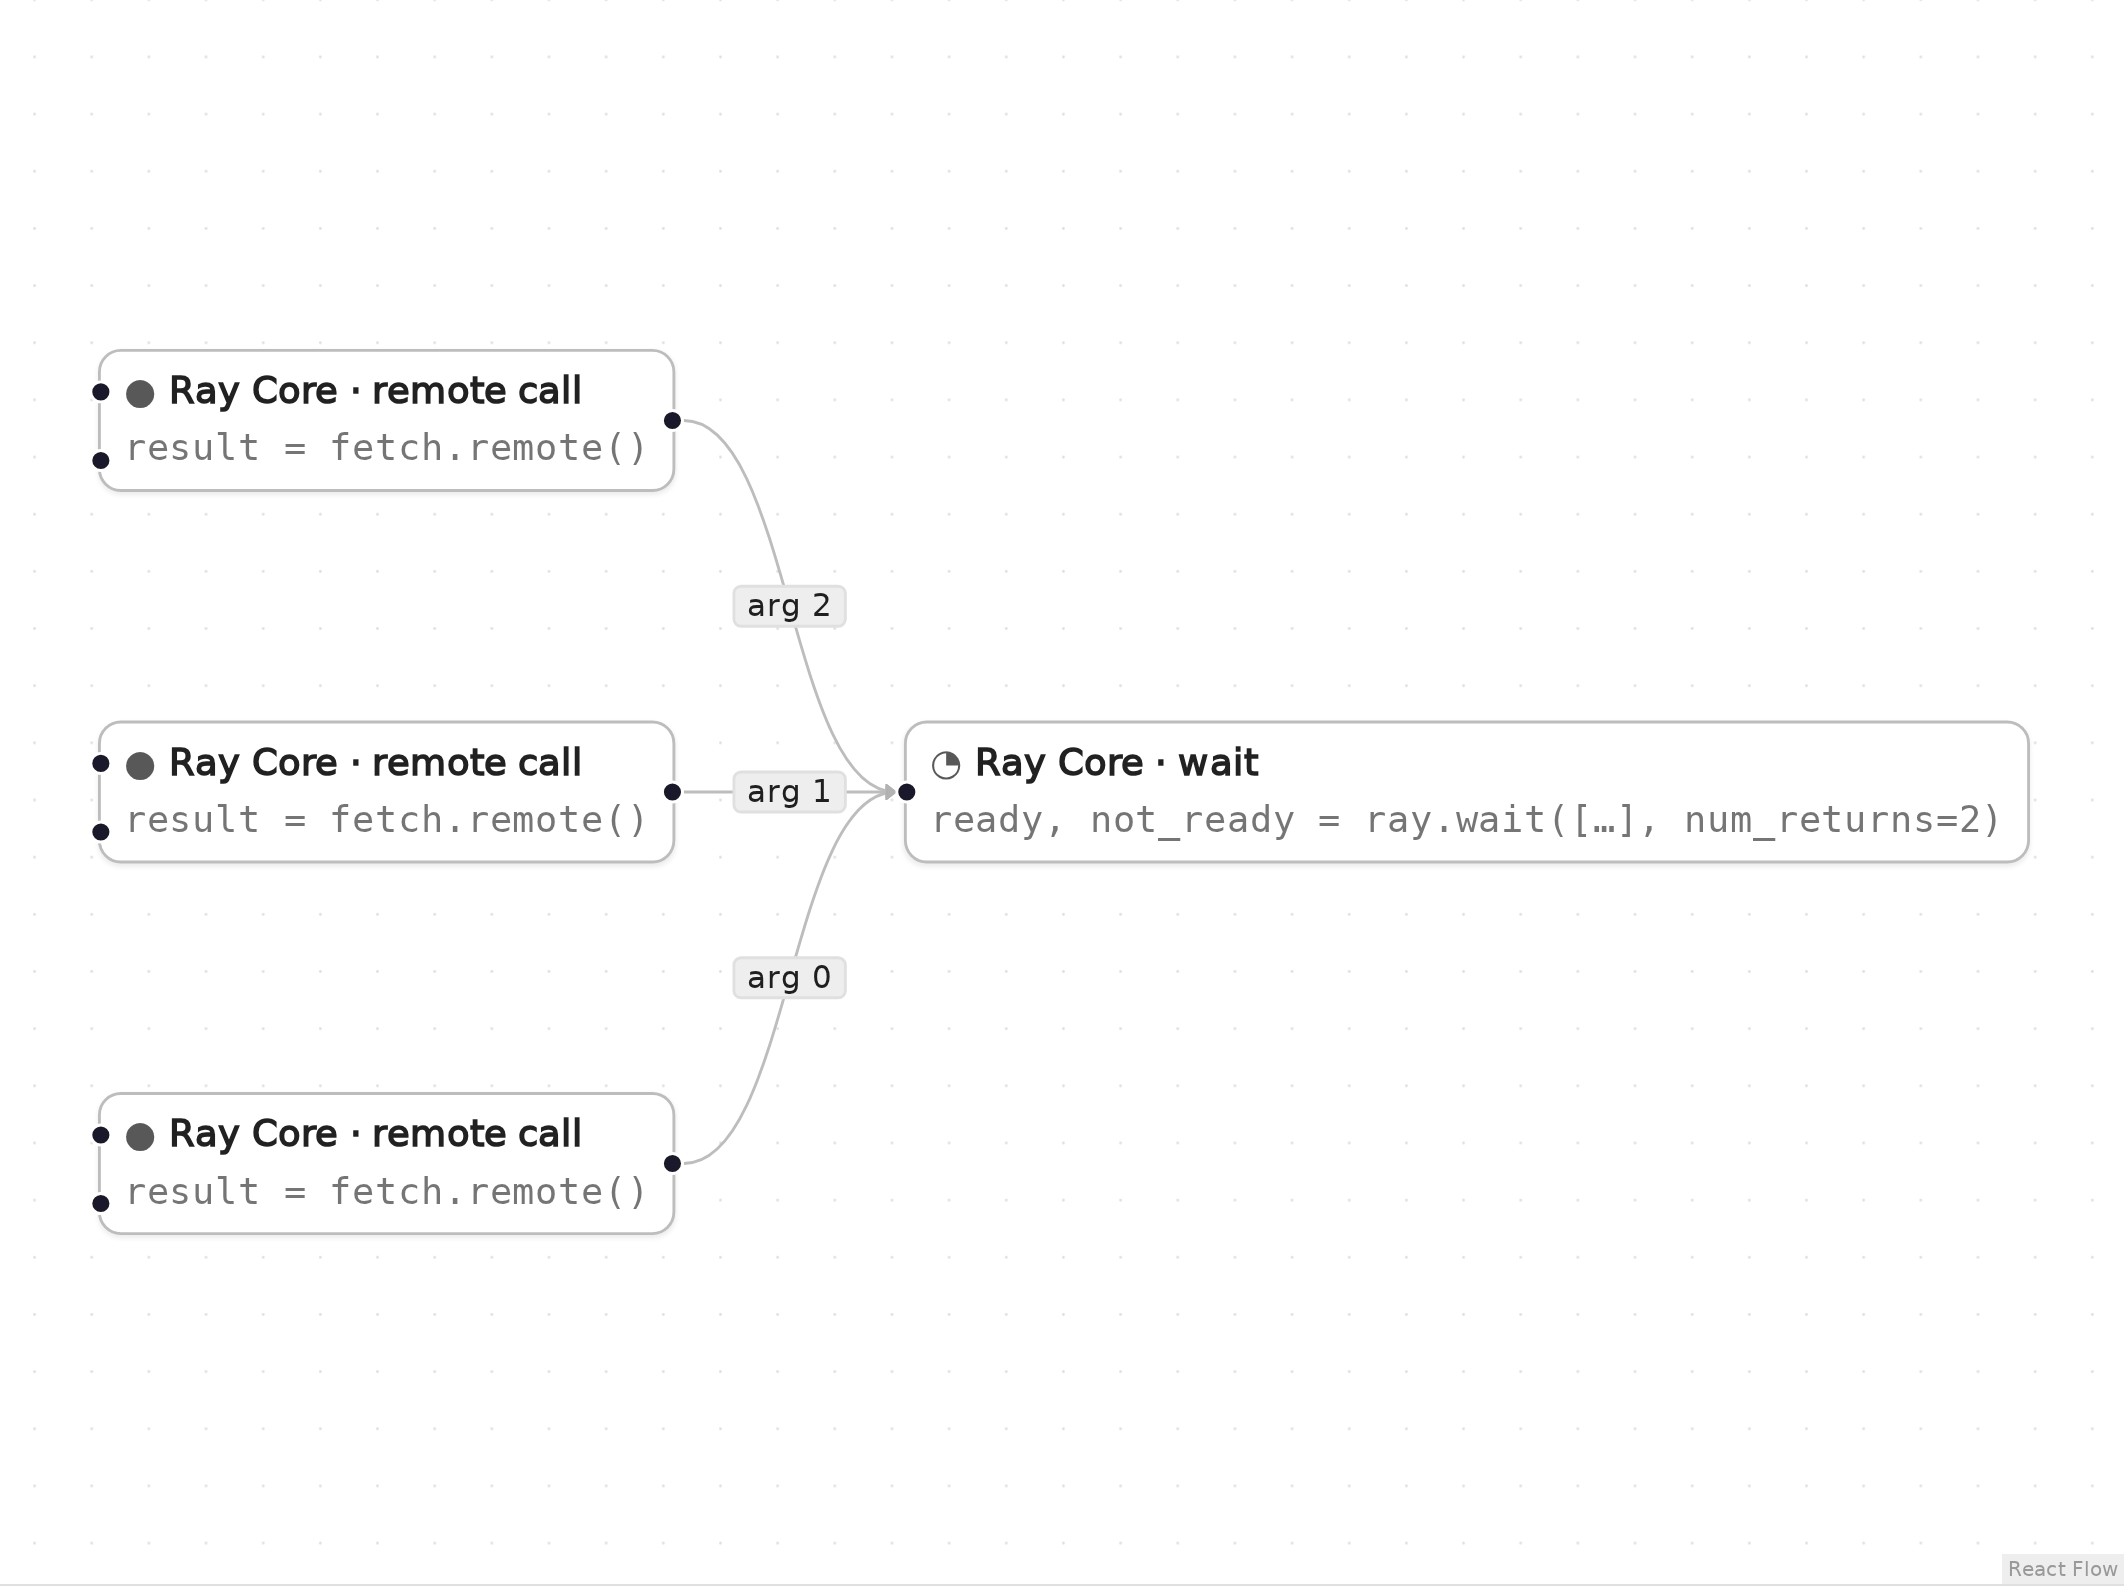

*The graph in Eugo's visual Ray builder.* All three tasks show `fetch.remote()`. From top to bottom they are `fetch(0.2)` (*arg 2*), the slow `fetch(5.0)` (*arg 1*) and `fetch(0.1)` (*arg 0*).

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import time


def fetch(delay):
    time.sleep(delay)
    return delay

## Generated code

This is the cell the visual builder generated from the graph above, with one edit by hand. The builder wrote `ray.remote(fetch)` at each of the three task calls, and every `ray.remote(...)` call makes a new remote function that Ray exports to the cluster again; Ray's documentation lists this as an anti-pattern ([Redefining the same remote function or class harms performance](https://docs.ray.io/en/latest/ray-core/patterns/redefine-task-actor-loop.html)). The cell below wraps `fetch` once and reuses it.

In [3]:
# Generated with Eugo's visual Ray builder, then edited by hand: each function is wrapped with ray.remote once

import ray

if not ray.is_initialized():
    ray.init()

fetch_task = ray.remote(fetch)

_n1 = fetch_task.remote(0.1)
_n2 = fetch_task.remote(5.0)
_n3 = fetch_task.remote(0.2)
ready_w1, not_ready_w1 = ray.wait([_n1, _n2, _n3], num_returns=2, timeout=30)
first_two = ray.get(ready_w1)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert sorted(first_two) == [0.1, 0.2], first_two
assert len(not_ready_w1) == 1
print("first two finished:", sorted(first_two))

first two finished: [0.1, 0.2]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder, then edited by hand: each function is wrapped with ray.remote once
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated and names the edit made by hand. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote function** (line 8, edited by hand)

```python
fetch_task = ray.remote(fetch)
```

ray.remote turns the plain function into a remote function, once; the three task nodes below call .remote() on it.

**Remote task** (node `n1`, line 10)

```python
_n1 = fetch_task.remote(0.1)
```

A fast task (0.1 s).

**Remote task** (node `n2`, line 11)

```python
_n2 = fetch_task.remote(5.0)
```

A slow task (5 s). It is still running when ray.wait returns.

**Remote task** (node `n3`, line 12)

```python
_n3 = fetch_task.remote(0.2)
```

Another fast task (0.2 s).

**Wait** (node `w1`, lines 13–14)

```python
ready_w1, not_ready_w1 = ray.wait([_n1, _n2, _n3], num_returns=2, timeout=30)
first_two = ray.get(ready_w1)
```

ray.wait splits the refs into ready and not-ready lists once num_returns=2 are done (or after the 30 s timeout); ray.get then fetches only the ready ones.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()